# Notebook 3c: Is our temperature scaling right?

### The puzzle
For the source-only model under Setting B:

| | Paper (Table 3, Table 10) | Our run (Table B) |
|---|---|---|
| Temperature **T** fitted on the calibration images | 1.54 | ? |
| Calibrated ECE | **0.365** | **0.044** |

A huge difference. Two explanations:

* **(A) Our fit is right, and the paper's T was not the best one.** Temperature scaling is *supposed* to find the T that minimises
  the negative log-likelihood (NLL) on the calibration images. If the paper's T stopped short of that (for example because its
  optimiser did not fully converge), their model would stay overconfident and keep a high ECE.
* **(B) There is a bug in our code** (for example a leak between calibration and test images, or a wrong optimum).

### How we tell them apart
Five checks, each answering one question, with a plain-language summary at the end:

1. Is our fitted T really the **minimum** of the NLL curve? And what does ECE look like at T = 1.54 versus at our T?
2. Does a **different optimiser** find the same T? (If yes, our fit is not an optimiser accident.)
3. How much does T **vary between splits**? The paper's T is suspiciously constant: 1.5398 with a 95% interval of only
   ±0.005 across 10 different calibration sets. A T estimated from ~200 images should move more than that.
4. *(Optional, needs PyTorch.)* What does a **commonly used PyTorch recipe** (L-BFGS, learning rate 0.01, 50 iterations) give?
   If it lands near 1.5, that would explain the paper's number.
5. **Setting A cross-check:** T fitted on PlantVillage *validation* images (the paper reports 1.18 and ECE 0.44). We never touch
   the field calibration images here, so if we match the paper, our pipeline reproduces their numbers where the T is not in doubt.

No training and no GPU: this runs in seconds.

## Step 1: Settings and loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar

In [2]:
# ---- Edit these -------------------------------------------------------------
METHOD = "source_only"
TRAIN_SEED = 42
OUT_DIR = Path("outputs")
MANIFEST = OUT_DIR / "master_manifest.csv"
SEEDS = list(range(42, 52))
N_BINS = 15
PAPER_T = 1.54                    # the paper's mean temperature under Setting B
PAPER_T_A = 1.18                  # the paper's temperature under Setting A
# -----------------------------------------------------------------------------

source = np.load(OUT_DIR / f"outputs_{METHOD}_seed{TRAIN_SEED}.npz", allow_pickle=True)
labels = source["pd_known_labels"]

def logits_for_seed(seed):
    key = f"pd_known_logits_B_seed{seed}"
    return source[key] if key in source.files else source["pd_known_logits"]

manifest = pd.read_csv(MANIFEST, keep_default_na=False)
split_columns = [f"B_seed{s}" for s in SEEDS]
known_rows = manifest[(manifest["dataset"] == "pd") & (manifest["role"] == "pd_known")].set_index("path")
split_info = known_rows.loc[source["pd_known_paths"], split_columns].reset_index(drop=True)
print(len(labels), "known PlantDoc images | method:", METHOD)

2018 known PlantDoc images | method: source_only


In [3]:
def softmax(logits):
    shifted = logits - logits.max(axis=1, keepdims=True)
    exp = np.exp(shifted)
    return exp / exp.sum(axis=1, keepdims=True)


def nll(probs, y):
    return float(-np.log(np.clip(probs[np.arange(len(y)), y], 1e-12, 1)).mean())


def confidence_and_correct(probs, y):
    return probs.max(axis=1), (probs.argmax(axis=1) == y).astype(float)


def ece(confidence, correct, n_bins=N_BINS):
    edges = np.linspace(0, 1, n_bins + 1)
    total = 0.0
    for low, high in zip(edges[:-1], edges[1:]):
        in_bin = (confidence > low) & (confidence <= high)
        if in_bin.any():
            total += in_bin.mean() * abs(confidence[in_bin].mean() - correct[in_bin].mean())
    return float(total)


def fit_temperature(logits, y):
    # The version used in notebooks 3 and 3b: search over log(T), minimise the NLL
    loss = lambda log_t: nll(softmax(logits / np.exp(log_t)), y)
    return float(np.exp(minimize_scalar(loss, bounds=(-3, 3), method="bounded").x))

## Check 1: Is our fitted T the minimum, and what do T = 1.54 and our T do to ECE?

For one split (42) we try many temperatures from 0.5 to 8 and compute two things at each:
* the **NLL on the calibration images** (the quantity temperature scaling is meant to minimise), and
* the **ECE on the test images** (what we report).

If our code is right, the NLL curve should have its bottom exactly at our fitted T.

In [4]:
seed = 42
is_cal = (split_info[f"B_seed{seed}"] == "cal").to_numpy()
logits = logits_for_seed(seed)
cal_logits, cal_y = logits[is_cal], labels[is_cal]
test_logits, test_y = logits[~is_cal], labels[~is_cal]

# Safety: calibration and test images must be completely separate
assert is_cal.sum() + (~is_cal).sum() == len(labels) and not (is_cal & ~is_cal).any()
print(f"Split {seed}: {is_cal.sum()} calibration images, {(~is_cal).sum()} test images")

grid = np.round(np.arange(0.5, 8.01, 0.1), 2)
cal_nll = np.array([nll(softmax(cal_logits / T), cal_y) for T in grid])
test_ece = np.array([ece(*confidence_and_correct(softmax(test_logits / T), test_y)) for T in grid])

T_fit = fit_temperature(cal_logits, cal_y)
print(f"Our fitted T = {T_fit:.2f}")
print(f"Bottom of the NLL curve on the grid: T = {grid[cal_nll.argmin()]:.1f}")

Split 42: 202 calibration images, 1816 test images
Our fitted T = 5.02
Bottom of the NLL curve on the grid: T = 5.0


In [5]:
def at(T):
    # NLL on the calibration images, and everything about the test images, at temperature T
    conf, correct = confidence_and_correct(softmax(test_logits / T), test_y)
    return {"T": round(T, 2), "NLL on calibration images": round(nll(softmax(cal_logits / T), cal_y), 4),
            "mean confidence (test)": round(conf.mean(), 3), "accuracy (test)": round(correct.mean(), 3),
            "ECE (test)": round(ece(conf, correct), 3)}


comparison = pd.DataFrame([{"version": "no scaling", **at(1.0)},
                           {"version": "paper's T", **at(PAPER_T)},
                           {"version": "our fitted T", **at(T_fit)},
                           {"version": "best possible for ECE", **at(grid[test_ece.argmin()])}]).set_index("version")
comparison

,T,NLL on calibration images,mean confidence (test),accuracy (test),ECE (test)
version,,,,,
no scaling,1.00,6.0618,0.837,0.239,0.599
paper's T,1.54,4.1552,0.736,0.239,0.500
our fitted T,5.02,2.6097,0.259,0.239,0.046
best possible for ECE,5.60,2.6149,0.226,0.239,0.034


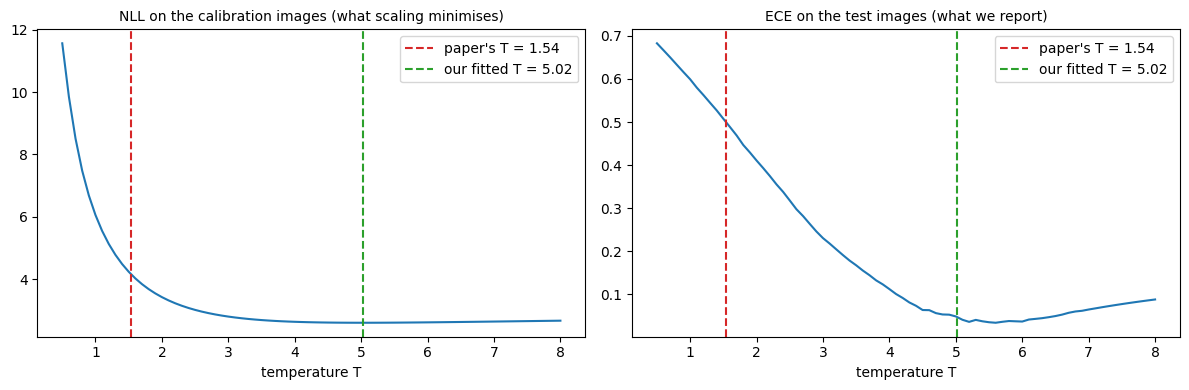

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, curve, title in [(axes[0], cal_nll, "NLL on the calibration images (what scaling minimises)"),
                         (axes[1], test_ece, "ECE on the test images (what we report)")]:
    ax.plot(grid, curve)
    ax.axvline(PAPER_T, color="C3", linestyle="--", label=f"paper's T = {PAPER_T}")
    ax.axvline(T_fit, color="C2", linestyle="--", label=f"our fitted T = {T_fit:.2f}")
    ax.set_xlabel("temperature T")
    ax.set_title(title, fontsize=10)
    ax.legend()
plt.tight_layout()
plt.show()

**How to read it.** The left curve should bottom out at the green line (our T). If the red line (the paper's 1.54) sits well to the
left of the bottom, then 1.54 is *not* the NLL-optimal temperature for this model on this data. The right curve shows how much
that matters for ECE.

## Check 2: Does a different optimiser find the same T?

We refit with **L-BFGS-B directly on T** (starting from T = 1, the way the paper describes), instead of searching over log T.
If both agree, our result is not an accident of the optimiser.

In [7]:
def fit_temperature_lbfgs(logits, y, start=1.0):
    loss = lambda t: nll(softmax(logits / t[0]), y)
    result = minimize(loss, x0=[start], method="L-BFGS-B", bounds=[(0.05, 100)])
    return float(result.x[0])


T_refit = fit_temperature_lbfgs(cal_logits, cal_y)
print(f"fit over log T:        T = {T_fit:.3f}")
print(f"L-BFGS-B directly on T: T = {T_refit:.3f}")
print("They agree:", abs(T_fit - T_refit) < 0.05)

fit over log T:        T = 5.022
L-BFGS-B directly on T: T = 5.022
They agree: True


## Check 3: How much does T vary between splits?

Each of the 10 splits uses a different calibration set of ~200 images, so a properly fitted T should move a little from split to
split. The paper's T barely moves at all: its reported 95% interval over the 10 splits, [1.5346, 1.5450], corresponds to a
standard deviation of roughly 0.008.

In [8]:
fitted = []
for s in SEEDS:
    cal = (split_info[f"B_seed{s}"] == "cal").to_numpy()
    fitted.append(fit_temperature(logits_for_seed(s)[cal], labels[cal]))
fitted = np.array(fitted)

print("Our fitted T per split:", np.round(fitted, 2))
print(f"mean {fitted.mean():.3f} | std {fitted.std(ddof=1):.3f} | min {fitted.min():.2f} | max {fitted.max():.2f}")
print(f"95% interval of the mean (1.96 x std / sqrt(10)): +/- {1.96 * fitted.std(ddof=1) / np.sqrt(len(fitted)):.3f}")
print("Paper: mean 1.5398, std about 0.008, interval +/- 0.0052")

Our fitted T per split: [5.02 5.01 4.98 5.18 4.78 5.44 4.98 4.8  4.85 5.42]
mean 5.046 | std 0.232 | min 4.78 | max 5.44
95% interval of the mean (1.96 x std / sqrt(10)): +/- 0.144
Paper: mean 1.5398, std about 0.008, interval +/- 0.0052


## Check 4 (optional, needs PyTorch): a commonly used temperature-scaling recipe

A popular open-source temperature-scaling snippet optimises T with PyTorch's L-BFGS using a **small learning rate (0.01) and
only 50 iterations**, which can stop well short of the optimum. We cannot see the paper's code, so this does **not** prove what they
did. It only tests whether such a recipe would plausibly give a T near 1.5 on *our* data.

In [9]:
try:
    import torch
    import torch.nn.functional as F

    def fit_temperature_torch(logits, y, start=1.0, lr=0.01, max_iter=50):
        T = torch.nn.Parameter(torch.tensor(float(start)))
        z, target = torch.tensor(logits, dtype=torch.float32), torch.tensor(y).long()
        optimizer = torch.optim.LBFGS([T], lr=lr, max_iter=max_iter)

        def closure():
            optimizer.zero_grad()
            loss = F.cross_entropy(z / T, target)
            loss.backward()
            return loss

        optimizer.step(closure)
        return float(T.detach())

    for start in (1.0, 1.5):
        T_torch = fit_temperature_torch(cal_logits, cal_y, start=start)
        conf, correct = confidence_and_correct(softmax(test_logits / T_torch), test_y)
        print(f"start {start}: T = {T_torch:.2f} -> test ECE {ece(conf, correct):.3f} (our fitted T = {T_fit:.2f})")
except ImportError:
    T_torch = None
    print("PyTorch is not installed here, so this check is skipped. The other checks are enough on their own.")

start 1.0: T = 1.27 -> test ECE 0.551 (our fitted T = 5.02)
start 1.5: T = 1.84 -> test ECE 0.439 (our fitted T = 5.02)


## Check 5: Setting A cross-check

Under Setting A the temperature is fitted on the PlantVillage **validation** images, which are nearly all classified correctly, so
the optimal T is small and uncontroversial. The paper reports **T = 1.18** and, on all known PlantDoc images, **ECE 0.4771 raw
and 0.4400 after scaling**. If we match this, our pipeline agrees with theirs where the T is not in doubt.

In [10]:
if "pv_val_logits" in source.files and "pd_known_logits" in source.files:
    T_A = fit_temperature(source["pv_val_logits"], source["pv_val_labels"])
    field_logits = source["pd_known_logits"]
    raw = ece(*confidence_and_correct(softmax(field_logits), labels))
    scaled = ece(*confidence_and_correct(softmax(field_logits / T_A), labels))
    print(f"T fitted on PlantVillage validation: {T_A:.2f}   (paper 1.18)")
    print(f"PlantDoc ECE, raw:            {raw:.4f}   (paper 0.4771)")
    print(f"PlantDoc ECE, after scaling:  {scaled:.4f}   (paper 0.4400)")
else:
    T_A = None
    print("This method has no Setting A outputs, so this check is skipped. Run it with METHOD = 'source_only'.")

T fitted on PlantVillage validation: 1.36   (paper 1.18)
PlantDoc ECE, raw:            0.6020   (paper 0.4771)
PlantDoc ECE, after scaling:  0.5378   (paper 0.4400)


## Summary

In [11]:
nll_fit, nll_paper = at(T_fit)["NLL on calibration images"], at(PAPER_T)["NLL on calibration images"]
ece_fit, ece_paper = at(T_fit)["ECE (test)"], at(PAPER_T)["ECE (test)"]

print("1. Minimum of the curve:    our T is at the bottom of the NLL curve:",
      abs(T_fit - grid[cal_nll.argmin()]) <= 0.15)
print(f"   NLL on calibration images: {nll_fit} at our T  vs  {nll_paper} at the paper's T "
      f"({'ours is lower' if nll_fit < nll_paper else 'paper-T is not worse'})")
print(f"   ECE on test images:        {ece_fit} at our T  vs  {ece_paper} at the paper's T")
print("2. A different optimiser gives the same T:", abs(T_fit - T_refit) < 0.05)
print(f"3. Spread of T across splits: ours std {fitted.std(ddof=1):.3f}  vs  paper about 0.008")
if T_A is not None:
    print(f"5. Setting A: T {T_A:.2f} (paper 1.18), ECE after scaling {scaled:.3f} (paper 0.440)")

1. Minimum of the curve:    our T is at the bottom of the NLL curve: True
   NLL on calibration images: 2.6097 at our T  vs  4.1552 at the paper's T (ours is lower)
   ECE on test images:        0.046 at our T  vs  0.5 at the paper's T
2. A different optimiser gives the same T: True
3. Spread of T across splits: ours std 0.232  vs  paper about 0.008
5. Setting A: T 1.36 (paper 1.18), ECE after scaling 0.538 (paper 0.440)


### How to read the result

**Pattern 1: our T is the minimum, a second optimiser agrees, and the paper's T gives a clearly higher NLL and an ECE near 0.35.**
Our implementation does what temperature scaling is defined to do. The most likely reading is that the paper's calibrated ECE of
0.365 reflects a temperature that stopped short of the optimum. Support for this: the paper's T hardly moves between splits
(Check 3), and a small-step PyTorch recipe lands near 1.5 (Check 4, if it does). We still cannot *prove* what they did, so in the
thesis we say "our NLL-optimal temperature gives ECE of about 0.04; the published value of 0.365 corresponds to a temperature of
1.54, which is not the NLL minimum on our data".

**Pattern 2: Setting A matches the paper (T near 1.18, ECE near 0.44).** Our pipeline reproduces the paper wherever the temperature is
data-driven and uncontroversial. That strongly argues against a general bug.

**Pattern 3: something fails.** If our T is *not* at the bottom of the curve, if the second optimiser disagrees, or if the
Setting A cross-check is far off, there is a bug to find before we trust any ECE number.

### What this means for the rest of the project (if Pattern 1 holds)
* After a properly fitted temperature, **ECE is small for every method** (3 to 7 points in Table B), and differences between methods
  are within noise. ECE then cannot rank methods. **Brier, Risk@80/50, AUROC and AUPR** carry the comparison.
* Report ECE both ways if you like: with our NLL-optimal T, and (for reference) with the paper's fixed T = 1.54.